# 06 - Consolidated tape (SIP, 5-min), a panel of 15 pairs, and earnings windows

Notebook 05 used the free IEX feed (2-3% of volume, from mid-2020). A free Alpaca key also gives the **SIP** feed: the *consolidated tape*, i.e. trades from **all** US exchanges,
from 2016 (delayed by 15 min for recent data, irrelevant for us). Consequences:
- **5-minute bars** instead of 15, from **2016-01-04**: about **1951 test days** instead of 800;
- RV is computed from the whole market's trades, not from a 2-3% sample, so it is much less noisy.

## Concepts
| Concept | Meaning |
|---|---|
| **SIP / consolidated tape** | Securities Information Processor: merges trades and quotes from all exchanges into one official feed. IEX is only one exchange. |
| **Pre-specified panel** | A list of pairs fixed *before* looking at results, so we cannot pick the winners afterwards (p-hacking). Articles with broken history (renamed Wikipedia pages: Amazon, Meta) were excluded by a data-quality filter before computing any result. |
| **Pooled test** | One test for the *average* effect across all pairs (cross-pair mean of the loss differential, then HAC): a single hypothesis, so no multiple-testing penalty, and more power than 15 separate tests. |
| **Earnings announcement** | Quarterly company results; a major scheduled information event. Volatility spikes on the **reaction day** (the day after if released after the close, the same day if before the open). The date is known in advance, so an `earn` dummy is a legitimate control. |
| **Event-window test** | Evaluate the attention gain only on the ~31 reaction days of each company: if attention matters, it should matter most when news arrives. |

In [1]:
import os, sys, warnings
os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import model_pipeline as mp, intraday as it, panel as pn
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": .3})
START, END = "2016-01-01", "2026-10-31"
# bars/views/earnings dates are cached in data/ (not committed); re-downloading needs ALPACA_KEY / ALPACA_SECRET

## 1. The six original pairs on SIP 5-minute data

In [2]:
d = pd.read_csv("results/intraday_sip_results.csv")
ols = d[d.model == "ols"]
ols[["ticker", "page", "dow", "n_oos", "r2_oos_baseline", "r2_oos_gain", "p_dm", "p_cw", "p_cw_holm"]].round(4)

,ticker,page,dow,n_oos,r2_oos_baseline,r2_oos_gain,p_dm,p_cw,p_cw_holm
0,QQQ,Nvidia,False,1951,0.5885,0.0040,0.0164,0.0003,0.0020
1,QQQ,Nvidia,True,1951,0.5957,0.0012,0.1523,0.0293,0.1466
4,SPY,Federal_Reserve,False,1951,0.6166,0.0055,0.1412,0.0005,0.0024
5,SPY,Federal_Reserve,True,1951,0.6272,0.0024,0.2293,0.0097,0.0579
8,XLE,Petroleum,False,1951,0.7177,-0.0071,0.9371,0.2232,0.2232
9,XLE,Petroleum,True,1951,0.7138,-0.0019,0.8362,0.4883,1.0000
12,XLF,JPMorgan_Chase,False,1951,0.6663,0.0026,0.1779,0.0053,0.0160
13,XLF,JPMorgan_Chase,True,1951,0.6703,-0.0006,0.7252,0.4707,1.0000
16,XLK,Apple_Inc.,False,1951,0.5798,0.0007,0.2893,0.0993,0.1986
17,XLK,Apple_Inc.,True,1951,0.5873,-0.0012,0.8220,0.6453,1.0000


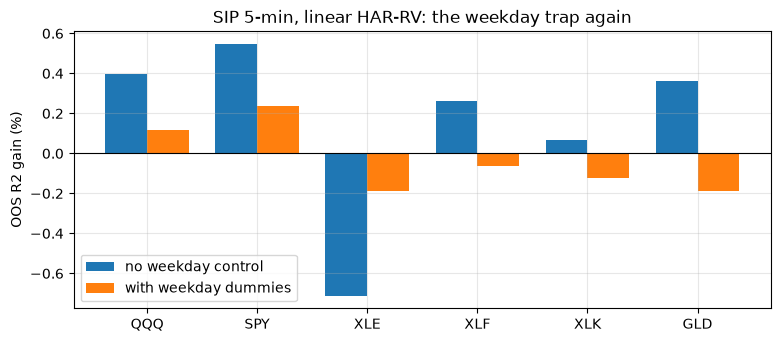

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
a = ols[~ols.dow].set_index("ticker"); b = ols[ols.dow].set_index("ticker"); x = np.arange(len(a)); w = .38
ax.bar(x - w/2, 100*a.r2_oos_gain, w, label="no weekday control"); ax.bar(x + w/2, 100*b.r2_oos_gain, w, label="with weekday dummies")
ax.set_xticks(x); ax.set_xticklabels(a.index); ax.axhline(0, color="k", lw=.8); ax.legend()
ax.set_ylabel("OOS R2 gain (%)"); ax.set_title("SIP 5-min, linear HAR-RV: the weekday trap again"); plt.show()

Same story as notebook 05 but with more data: **without** the weekday control four pairs look significant (adjusted p between 0.002 and 0.016); **with** it nothing survives Holm
(best: SPY/Fed 0.058, QQQ/Nvidia 0.147). The baseline $R^2$ is higher (0.44-0.72) because SIP RV is a cleaner measurement.

## 2. Panel of 15 pre-specified pairs (weekday and earnings controls in both models)

In [4]:
pr = pd.read_csv("results/panel_results.csv")
pr[["etf", "page", "r2_oos_baseline", "r2_oos_gain", "p_dm", "p_cw", "p_cw_holm"]].round(4)

,etf,page,r2_oos_baseline,r2_oos_gain,p_dm,p_cw,p_cw_holm
0,QQQ,Nvidia,0.5955,0.0010,0.1862,0.0353,0.4943
1,QQQ,Apple_Inc.,0.5963,-0.0022,0.8389,0.5639,1.0000
2,QQQ,Microsoft,0.5968,-0.0011,0.9461,0.8968,1.0000
3,QQQ,Alphabet_Inc.,0.5951,-0.0008,0.6605,0.2330,1.0000
4,XLK,Apple_Inc.,0.5883,-0.0012,0.8214,0.6421,1.0000
5,XLK,Microsoft,0.5891,-0.0014,0.9534,0.8915,1.0000
6,XLK,Nvidia,0.5873,0.0010,0.2586,0.0374,0.4943
7,XLF,JPMorgan_Chase,0.6724,-0.0008,0.7872,0.5644,1.0000
8,XLF,Bank_of_America,0.6702,-0.0003,0.6640,0.4454,1.0000
9,XLF,Goldman_Sachs,0.6699,-0.0009,0.6654,0.2983,1.0000


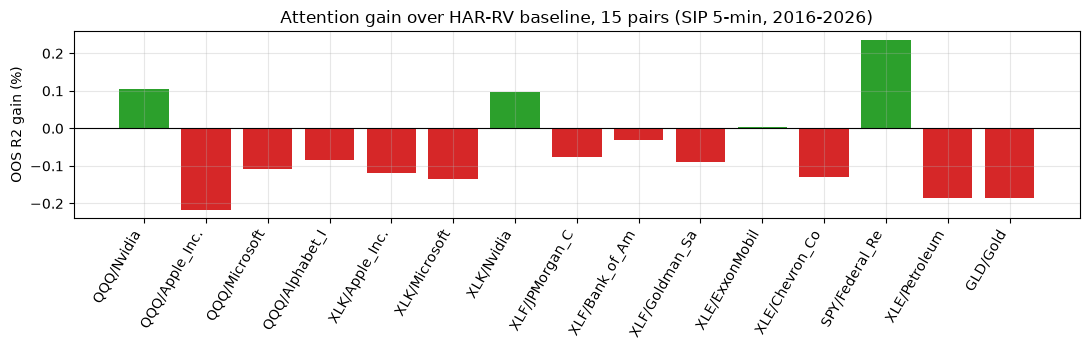

mean gain: -0.061 %, negative in 11 of 15 pairs


,test,stat,p,n_pairs,n_days
0,pooled_CW_all_pairs,1.96373,0.02478,15,1951


In [5]:
fig, ax = plt.subplots(figsize=(11, 3.6))
lab = pr.etf + "/" + pr.page.str[:10]
ax.bar(lab, 100*pr.r2_oos_gain, color=np.where(pr.r2_oos_gain > 0, "tab:green", "tab:red"))
ax.axhline(0, color="k", lw=.8); plt.xticks(rotation=60, ha="right"); ax.set_ylabel("OOS R2 gain (%)")
ax.set_title("Attention gain over HAR-RV baseline, 15 pairs (SIP 5-min, 2016-2026)"); plt.tight_layout(); plt.show()
print("mean gain: %.3f %%, negative in %d of %d pairs" % (100*pr.r2_oos_gain.mean(), (pr.r2_oos_gain < 0).sum(), len(pr)))
pd.read_csv("results/panel_pooled.csv")

**Reading.**
- Per pair, **no pair is significant after Holm** (best: SPY/Fed adjusted $p=0.145$).
- The **pooled Clark-West test** gives $p\approx0.025$ (one-sided): a weak, statistically detectable *average* effect. But look at the size: the mean OOS $R^2$ gain is about
  **-0.06%**, negative for 11 of 15 pairs. The pooled test is driven by a few pairs (Nvidia in QQQ and XLK, Fed in SPY), and Clark-West tests whether the extra
  coefficients carry *any* signal, not whether the forecast is practically better. Verdict: **at most a tiny signal, no usable improvement**.
- The two Nvidia pairs are not independent evidence (same company, same events); Nvidia's views are an outlier because it was a fast-growing attention stock.

## 3. Earnings windows

In [6]:
ev = pr.dropna(subset=["earn_p_cw"])
ev[["etf", "page", "company", "n_earn_days", "earn_r2_gain", "earn_cw_stat", "earn_p_cw", "earn_p_cw_holm"]].round(4)

,etf,page,company,n_earn_days,earn_r2_gain,earn_cw_stat,earn_p_cw,earn_p_cw_holm
0,QQQ,Nvidia,NVDA,31.0,0.0413,2.0158,0.0219,0.2410
1,QQQ,Apple_Inc.,AAPL,31.0,0.0102,1.1830,0.1184,0.9472
2,QQQ,Microsoft,MSFT,32.0,-0.0087,-1.8061,0.9646,1.0000
3,QQQ,Alphabet_Inc.,GOOGL,32.0,0.0109,1.2669,0.1026,0.9233
4,XLK,Apple_Inc.,AAPL,31.0,0.0075,1.3782,0.0841,0.8406
5,XLK,Microsoft,MSFT,32.0,-0.0117,-1.6590,0.9514,1.0000
6,XLK,Nvidia,NVDA,31.0,0.0507,2.1766,0.0148,0.1771
7,XLF,JPMorgan_Chase,JPM,31.0,0.0096,0.8938,0.1857,1.0000
8,XLF,Bank_of_America,BAC,31.0,-0.0160,-1.7384,0.9589,1.0000
9,XLF,Goldman_Sachs,GS,31.0,0.0092,0.7734,0.2196,1.0000


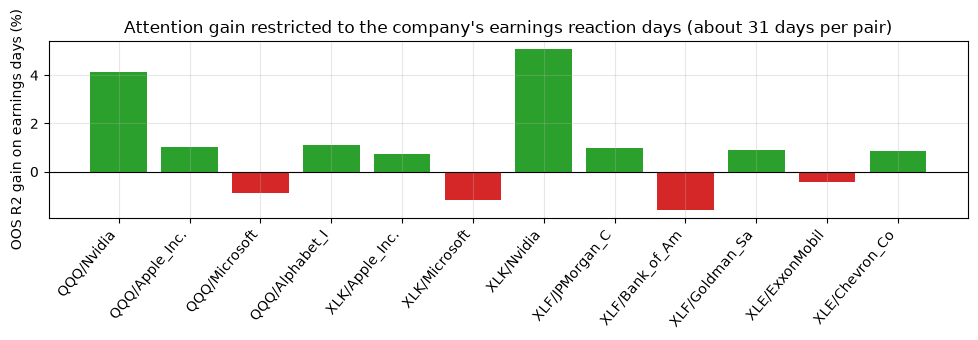

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(ev.etf + "/" + ev.page.str[:10], 100*ev.earn_r2_gain, color=np.where(ev.earn_r2_gain > 0, "tab:green", "tab:red"))
ax.axhline(0, color="k", lw=.8); plt.xticks(rotation=50, ha="right"); ax.set_ylabel("OOS R2 gain on earnings days (%)")
ax.set_title("Attention gain restricted to the company's earnings reaction days (about 31 days per pair)"); plt.tight_layout(); plt.show()

**Reading.** On earnings days the attention gain is larger in absolute terms (up to +5% for Nvidia) and positive for 8 of 12 pairs, which fits the idea that attention matters around news.
But there are only ~31 days per pair, and the two Nvidia hits (raw $p=0.015$ and $0.022$) become **$p=0.18$ and $0.24$ after Holm** over the 12 tests. *Suggestive, not significant.*
A dedicated study would need more events (more companies, a longer history of earnings-day intraday data, or event windows of several days).

## Conclusions
1. With consolidated-tape data and 1951 test days the conclusion is the same as before, now with much more power: **no pair shows a significant gain once calendar effects are controlled.**
2. The pooled test finds a statistically faint average signal ($p\approx0.025$) with a **negative mean OOS $R^2$ gain**: not economically useful.
3. Earnings windows: suggestive for Nvidia only; not significant after correction.
4. Remaining limits: 15 pairs of well-known large caps; Wikipedia pageviews only; yfinance earnings dates are unofficial (verified on synthetic cases, not against SEC filings);
   half-day sessions (about 3 per year) are not removed; a 5-minute RV still contains some microstructure noise (a subsampled or kernel estimator would reduce it).